<a href="https://colab.research.google.com/github/sh1vam31/Complete_DataScience/blob/main/logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Logistic Regression                   
This dataset is about predicting a person’s personality type (Introvert, Ambivert, or Extrovert) based on different psychological, social, and behavioral traits.



### Import all the required libraries

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Let's take a peek at our data         
We'll use `pandas` to read the CSV file and show the first 5 rows.

In [3]:
df = pd.read_csv("personality_synthetic_dataset.csv")
df

,personality_type,social_energy,alone_time_preference,talkativeness,deep_reflection,group_comfort,party_liking,listening_skill,empathy,creativity,...,spontaneity,adventurousness,reading_habit,sports_interest,online_social_usage,travel_desire,gadget_usage,work_style_collaborative,decision_speed,stress_handling
0,Extrovert,6.794295,3.854670,8.725446,2.515151,7.097368,8.588762,6.774799,6.430132,6.142968,...,4.853313,8.257134,5.270555,10.000000,9.154296,4.816422,9.191711,8.313590,8.032376,7.176905
1,Ambivert,6.378988,5.731157,7.029529,7.274493,4.111199,3.258248,5.550909,3.958179,6.149457,...,6.067201,6.289347,5.753165,5.334303,4.683781,4.725666,5.956141,5.890619,3.158988,3.423577
2,Ambivert,7.459421,6.322263,3.922269,4.622261,5.343276,7.452152,9.483990,6.127654,7.032017,...,5.524244,9.238784,5.250405,3.153540,5.000338,6.139166,6.033048,5.807500,4.571003,5.647480
3,Extrovert,6.159626,3.097837,6.019093,1.965440,7.837140,10.000000,9.436733,8.949684,8.923875,...,4.327018,8.489791,5.312617,8.379936,7.601946,6.370056,5.410145,6.671781,6.600233,5.870088
4,Introvert,5.568462,6.986722,3.913240,9.926161,1.650483,0.362298,7.470387,6.756837,9.507803,...,5.187689,3.167217,7.060235,2.333388,7.771569,5.534336,5.704598,5.832968,5.813099,3.758084
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3985,Ambivert,7.247988,6.918653,3.648131,6.188844,4.588180,3.363841,5.282220,8.677044,5.853673,...,5.571956,6.337916,6.121726,3.346005,6.792622,5.671899,8.464133,6.246632,3.646288,3.353850
3986,Introvert,4.938441,8.855670,1.917002,7.731968,1.105082,1.585159,10.000000,7.333904,7.461651,...,4.496509,0.511209,7.935622,2.375747,1.940867,4.452545,6.573441,4.023381,4.388377,5.212294
3987,Extrovert,5.906165,3.404246,1.763399,2.633642,9.379205,5.480171,6.716425,5.948289,4.887096,...,4.864278,4.187999,4.723593,7.968210,9.779934,7.769116,4.584757,5.414411,8.093853,7.753005
3988,Extrovert,9.509361,2.424060,6.231145,5.249645,8.850656,6.281846,5.570950,4.785368,7.575820,...,8.266894,8.552425,5.464911,10.000000,7.070117,6.413893,5.794344,8.260746,6.576382,3.693858


 Sometimes our dataset has empty spots, called missing values. We can use `df.isnull().sum()` to count how many missing values are in each column.

In [4]:
df.isnull().sum()

,0
personality_type,0
social_energy,0
alone_time_preference,0
talkativeness,0
deep_reflection,0
group_comfort,0
party_liking,0
listening_skill,0
empathy,0
creativity,0


In [5]:
df.duplicated().sum()

np.int64(0)

 Let's see all the columns in our dataset and what kind of data each column has (numbers, words, yes/no, etc.). This helps us understand our data better.


In [6]:
df.columns

Index(['personality_type', 'social_energy', 'alone_time_preference',
       'talkativeness', 'deep_reflection', 'group_comfort', 'party_liking',
       'listening_skill', 'empathy', 'creativity', 'organization',
       'leadership', 'risk_taking', 'public_speaking_comfort', 'curiosity',
       'routine_preference', 'excitement_seeking', 'friendliness',
       'emotional_stability', 'planning', 'spontaneity', 'adventurousness',
       'reading_habit', 'sports_interest', 'online_social_usage',
       'travel_desire', 'gadget_usage', 'work_style_collaborative',
       'decision_speed', 'stress_handling'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3990 entries, 0 to 3989
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   personality_type          3990 non-null   object 
 1   social_energy             3990 non-null   float64
 2   alone_time_preference     3990 non-null   float64
 3   talkativeness             3990 non-null   float64
 4   deep_reflection           3990 non-null   float64
 5   group_comfort             3990 non-null   float64
 6   party_liking              3990 non-null   float64
 7   listening_skill           3990 non-null   float64
 8   empathy                   3990 non-null   float64
 9   creativity                3990 non-null   float64
 10  organization              3990 non-null   float64
 11  leadership                3990 non-null   float64
 12  risk_taking               3990 non-null   float64
 13  public_speaking_comfort   3990 non-null   float64
 14  curiosit

Let's **count how many people belong to each personality type**.

<Axes: xlabel='personality_type', ylabel='count'>

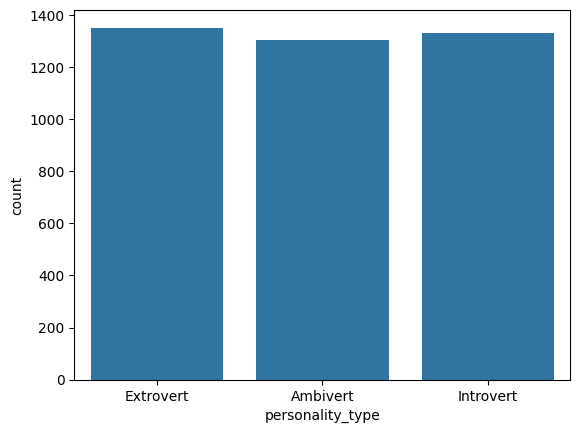

In [8]:
sns.countplot(x = df['personality_type'])

 We want to check **how many people have low, medium, or high social energy**.  
A histogram shows the **count of people** for different ranges of social energy. The line (KDE) shows the smooth trend.

<Axes: xlabel='social_energy', ylabel='Count'>

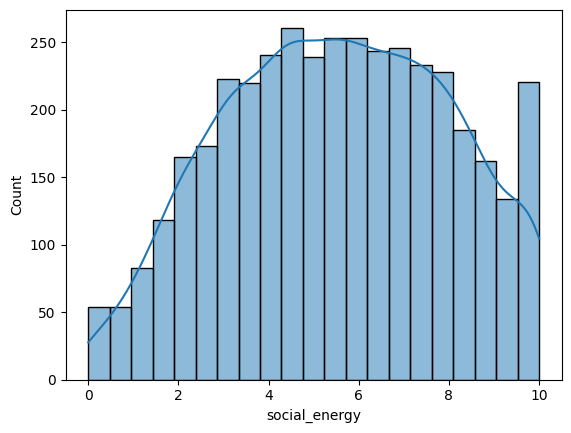

In [9]:
sns.histplot(df['social_energy'],kde = True)

 Let's use a pair plot and see how one column is related to another column                                                              This will help us to know that which columns are more related to each other.

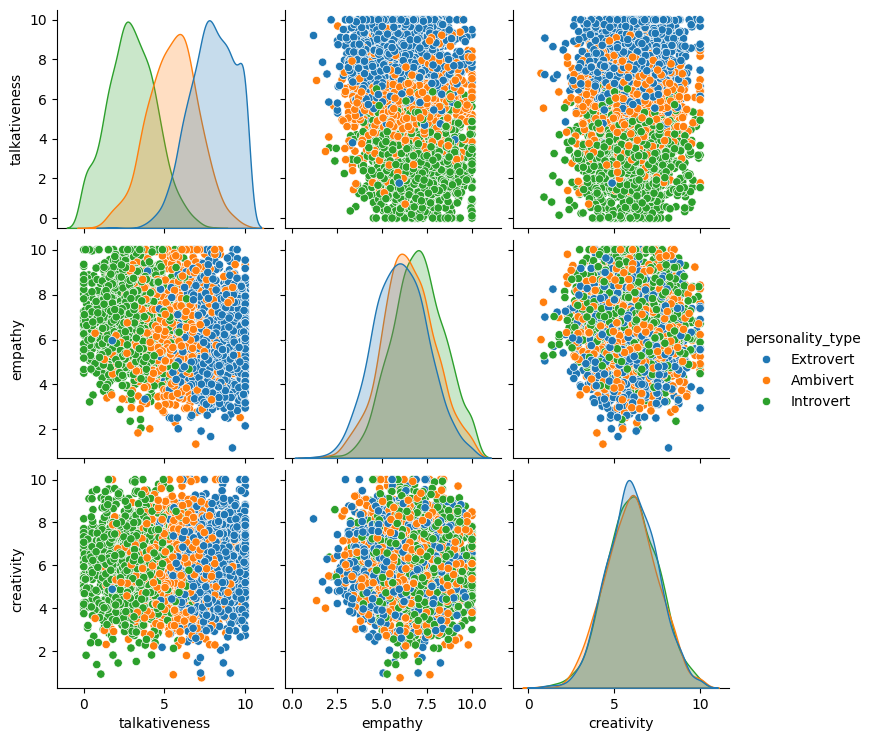

In [10]:
sns.pairplot(df[['talkativeness', 'empathy', 'creativity', 'personality_type']],hue = "personality_type")

In [11]:
from scipy.stats import f_oneway
annova_results = {}
for col in df.columns:
  if col == 'personality_type':
    continue

  groups = [group[col].values for name, group in df.groupby('personality_type')]

  f_stats, p_value = f_oneway(*groups)

  annova_results[col] = {"f_statistics" :f_stats, "p_value" : p_value}

annova_df = pd.DataFrame(annova_results).T

annova_df['significance (p<0.05)'] = annova_df['p_value'] < 0.05

annova_df = annova_df.sort_values(by = "f_statistics",ascending = False)

print(annova_df)

                          f_statistics        p_value  significance (p<0.05)
party_liking               5727.350153   0.000000e+00                   True
alone_time_preference      4139.347189   0.000000e+00                   True
public_speaking_comfort    3932.024954   0.000000e+00                   True
social_energy              3863.102838   0.000000e+00                   True
talkativeness              3849.633341   0.000000e+00                   True
excitement_seeking         3846.833905   0.000000e+00                   True
group_comfort              2496.144884   0.000000e+00                   True
adventurousness            2464.055772   0.000000e+00                   True
reading_habit              2401.488928   0.000000e+00                   True
leadership                 2400.151786   0.000000e+00                   True
risk_taking                2379.224771   0.000000e+00                   True
deep_reflection            2242.384218   0.000000e+00                   True

Machine learning models cannot understand text, so we have to convert `personality_type` to numbers using `LabelEncoder` from sklearn.preprocessing. This lets the model process and learn from it.

In [12]:
from sklearn.preprocessing import LabelEncoder,StandardScaler
le = LabelEncoder()
df['personality_type'] = le.fit_transform(df['personality_type'])

### Split X and y features.


In [13]:
X = df.drop(columns = ['personality_type','emotional_stability','stress_handling','creativity'])
y = df['personality_type']

This replaces each missing value with the mean of its respective column.

In [14]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

Machine learning models work better when all features are on the same scale, so we use `StandardScaler` from `sklearn.preprocessing` to transform the features. This makes each feature have a **mean of 0** and **standard deviation of 1**, helping the model learn efficiently.


In [15]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

To evaluate a machine learning model properly, we split the dataset into training and testing sets using `train_test_split` from `sklearn.model_selection`.
This keeps **80% of the data for training** and **20% for testing**, so the model can learn from one part and be evaluated on unseen data.

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42
)

Now we have finally splitted our data as test and train now let's create logistic regression model and we will import it from the

In [17]:
from sklearn.linear_model import LogisticRegression

In [18]:
model = LogisticRegression()

Once we have created our model now it's training time

In [19]:
model.fit(X_train,y_train)

LogisticRegression()

Awesome! The model is trained, and now we can use `.predict(X_test)` to generate predictions on the test set.


In [20]:
y_pred = model.predict(X_test)

### Lets create a confusion matrix to see the accuracy

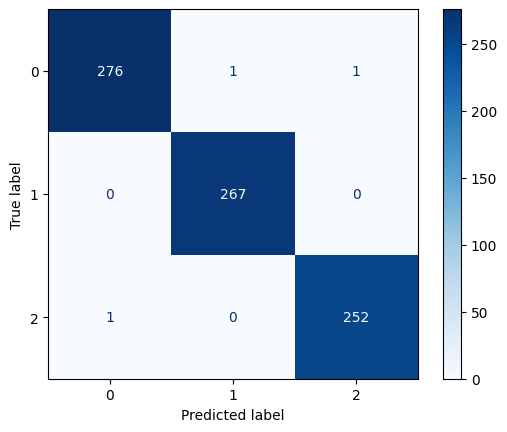

In [21]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm = confusion_matrix(y_test,y_pred)
cm
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap = "Blues")

Finally, let's evaluate our model’s performance using accuracy. We’ll apply `accuracy_score(y_test, y_pred)` which we will import from `sklearn.metrics`.


In [23]:
from sklearn.metrics import accuracy_score,classification_report
accuracy_score(y_test,y_pred)

0.9962406015037594

In [24]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       278
           1       1.00      1.00      1.00       267
           2       1.00      1.00      1.00       253

    accuracy                           1.00       798
   macro avg       1.00      1.00      1.00       798
weighted avg       1.00      1.00      1.00       798



pickle file -  A pickle file stores Python data or models so you can reuse them later without repeating the work.

In [26]:
import pickle
with open('personality_model.pkl', 'wb') as file:
    pickle.dump(model, file)

In [27]:
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)